<a href="https://colab.research.google.com/github/reitezuz/18NES2-2025/blob/main/week_09/time_series_jena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time series prediction - Jena Climate Dataset

Inspired by: https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter13_timeseries-forecasting.ipynb

# Jena Climate Dataset
The dataset contains meteorological data recorded in Jena, Germany, from 2009 to 2016. Measurement frequency: Every 10 minutes. It is suitable for time series analysis and weather prediction.
- File type: CSV (compressed in a ZIP file).

**Variables:**
- `Datetime` - Date and time of measurement.
- `Temperature (°C)` - Temperature.
- `Pressure (hPa)` - Atmospheric pressure.
- `Humidity (%)` - Relative humidity.
- `Wind speed (m/s)` - Wind speed.
- `Wind direction (°)` - Wind direction in degrees.
- `Radiation (W/m²)` - Solar radiation intensity.
- ...

**Uses:**
- Temperature or other meteorological variable prediction.
- Seasonal and trend analysis in time series data.

**Dataset Source:**

- Dataset download: [jena_climate_2009_2016.csv.zip](https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip)
- Kaggle: https://www.kaggle.com/datasets/mnassrib/jena-climate


## Load, observe and analyze the data

1. Download the zip file with the data
2. Extract the zip file

In [2]:
!wget https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
!unzip jena_climate_2009_2016.csv.zip

import os
# Clean up by removing the downloaded zip file
os.remove("jena_climate_2009_2016.csv.zip")


--2025-11-28 17:10:04--  https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip
Resolving s3.amazonaws.com (s3.amazonaws.com)... 16.15.188.224, 52.216.49.184, 16.182.64.40, ...
Connecting to s3.amazonaws.com (s3.amazonaws.com)|16.15.188.224|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13565642 (13M) [application/zip]
Saving to: ‘jena_climate_2009_2016.csv.zip’

jena_climate_2009_2 100%[===================>]  12.94M  20.7MB/s    in 0.6s    

2025-11-28 17:10:06 (20.7 MB/s) - ‘jena_climate_2009_2016.csv.zip’ saved [13565642/13565642]

Archive:  jena_climate_2009_2016.csv.zip
  inflating: jena_climate_2009_2016.csv  
  inflating: __MACOSX/._jena_climate_2009_2016.csv  


### Parse and observe the data

In [3]:
import pandas as pd
import numpy as np
import os

file_path = "jena_climate_2009_2016.csv"

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(file_path)

# Extract header and number of rows using pandas
header = list(df.columns)
num_rows = len(df)

# Extract 'Temperature (°C)' column into temperature array
temperature = df['T (degC)'].values

# Create raw_data array (excluding the Date Time column)
raw_data = df.drop(columns=['Date Time']).values

print("Header:", header)
print("Number of columns:", len(header))
print("Number of rows:", num_rows)
print("Temperature array shape:", temperature.shape)
print("Raw data array shape:", raw_data.shape)

# Example: Display first few rows of the DataFrame
print(df.head())


Header: ['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']
Number of columns: 15
Number of rows: 420451
Temperature array shape: (420451,)
Raw data array shape: (420451, 14)
             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.

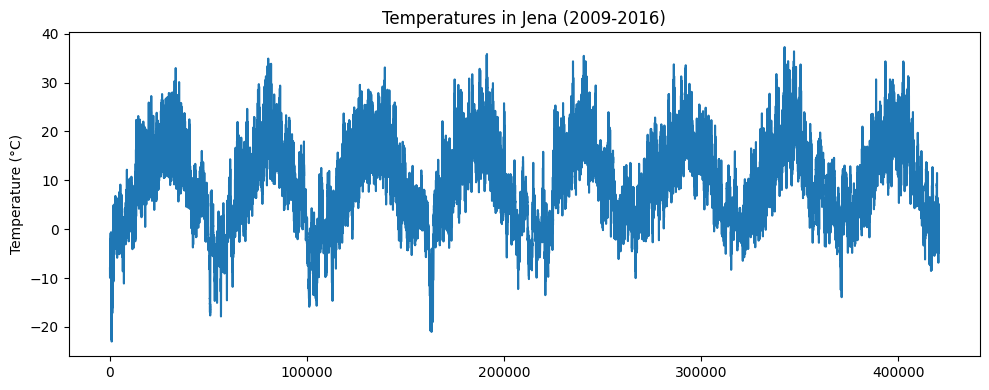

In [4]:
# Plotting the temperature timeseries
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(range(len(temperature)), temperature)
plt.title("Temperatures in Jena (2009-2016)")
#plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

#

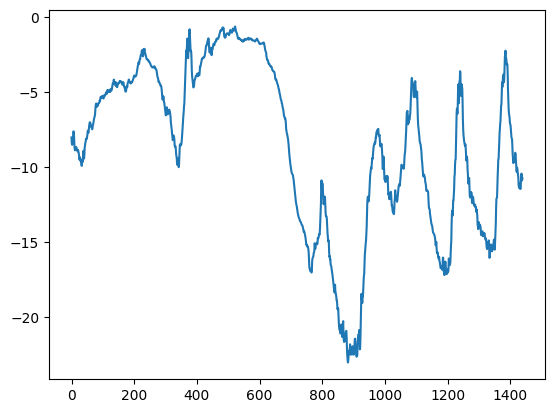

In [5]:
# Plotting the first 10 days of the temperature timeseries (24*6 = 144 points per day)
plt.plot(range(1440), temperature[:1440])

#### Observation
- We can observe periodicity over multiple timescales:
  - it is more reliable for months and less for days

### General example: creating a data loader for time series data
- create a data loader (dataset) for the time series data
- https://keras.io/api/data_loading/timeseries/

In [6]:
import numpy as np
import keras

int_sequence = np.arange(10) # 0,..,9
print(int_sequence)

dummy_dataset = keras.utils.timeseries_dataset_from_array(
    data=int_sequence[:-3],
    targets=int_sequence[3:],
    sequence_length=3,
    batch_size=2,
)

for inputs, targets in dummy_dataset:
    print("")
    for i in range(inputs.shape[0]):
        print([int(x) for x in inputs[i]], int(targets[i]))


[0 1 2 3 4 5 6 7 8 9]

[0, 1, 2] 3
[1, 2, 3] 4

[2, 3, 4] 5
[3, 4, 5] 6

[4, 5, 6] 7


### Our task

- We will use only data measured once per hour instead of all data (measured every 10 minutes).
- Based on the values from the previous 5 days, we will predict the temperature 24 hours ahead.
   - 24 points per day, 120 points in 5 days

### Prepare the data
- Normalize the data
- Divide the data into training (50%), validation (25%) and testing (25%) subset
  - The validation and test data should be more recent then the training data.

In [7]:
import numpy as np
import keras

# Training, validation and testing data
num_train_samples = int(0.5 * len(raw_data)) # 50 % training data
num_val_samples = int(0.25 * len(raw_data))  # 25 % validation and testing data
num_test_samples = len(raw_data) - num_train_samples - num_val_samples

# Normalize the data:
mean_data = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean_data
std_data = raw_data[:num_train_samples].std(axis=0)
raw_data /= std_data

# Create the training, validation and testing data sets:
sampling_rate = 6        # we will use each 6th sample (1 per hour)
sequence_length = 120    # we will use data from 120 hours (5 days)
delay = sampling_rate * (sequence_length + 24 - 1) # target: value 24 hours after the end of sequence
batch_size = 256

train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_train_samples)

val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples)

test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    #shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples + num_val_samples)


for samples, targets in train_dataset:
    print("samples shape:", samples.shape)
    print("targets shape:", targets.shape)
    break
print("Number of batches:", len(train_dataset))

samples shape: (256, 120, 14)
targets shape: (256,)
Number of batches: 819


In [8]:
# Data frame for results
import pandas as pd

columns = ["Model Name", "Details", "Train MAE", "Val MAE", "Test MAE", "Time (s)", "Epochs", "Train RMSE", "Val RMSE", "Test RMSE"]
results_df = pd.DataFrame(columns=columns)

## Baseline model: Naive last value predictor
- predict the temperature 24 hours ago (i.e., the last measured temperature)
- compute the error (MAE, RMSE) for the baseline model

In [9]:
def collect_naive_predictions(dataset, mean, std):
    preds_all = []
    targets_all = []

    for samples, targets in dataset:
        # last values * std + mean
        preds = samples[:, -1, 1] * std[1] + mean[1]
        targets = targets
        preds_all.append(preds)         # preds has shape (batch,)
        targets_all.append(targets)     # targets has shape (batch,)

    # concatenate batched results
    preds_all = np.concatenate(preds_all)
    targets_all = np.concatenate(targets_all)

    return preds_all, targets_all

In [10]:
# Predict on train, val, and test sets
y_train_base, y_train_true = collect_naive_predictions(train_dataset, mean_data, std_data)
y_val_base, y_val_true = collect_naive_predictions(val_dataset, mean_data, std_data)
y_test_base, y_test_true = collect_naive_predictions(test_dataset, mean_data, std_data)

# Compute metrics
def evaluate_baseline(y_true, y_pred, name=""):
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{name} MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return mae, rmse


train_mae, train_rmse = evaluate_baseline(y_train_true, y_train_base, "Train")
val_mae, val_rmse = evaluate_baseline(y_val_true, y_val_base, "Validation")
test_mae, test_rmse = evaluate_baseline(y_test_true, y_test_base, "Test")

# Add results to the dataframe:
new_entry = {
    "Model Name" : "Baseline",
    "Details" : "Previous day",
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": 0,
    "Time (s)": -1,
}

if results_df.empty or "results_df" not in globals():
    results_df = pd.DataFrame([new_entry])
else:
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
model_dir = "./models/"
if not os.path.exists(os.path.dirname(model_dir)):
    os.makedirs(os.path.dirname(model_dir))
results_df.to_csv("models/jena_results.csv", index=False)
results_df

Train MAE: 2.6916, RMSE: 3.4924
Validation MAE: 2.4417, RMSE: 3.1778
Test MAE: 2.6220, RMSE: 3.4268
Results:
  Model Name       Details  Train MAE   Val MAE  Test MAE  Train RMSE  \
0   Baseline  Previous day   2.691644  2.441733  2.622036    3.492441   

   Val RMSE  Test RMSE  Epochs  Time (s)  
0  3.177835   3.426826       0        -1  


,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1


## MLP model for time series (same as for regression):
- relu or tanh activation in hidden layers
- Linear activation in the output layer
- Loss: MeanSquaredError or MeanAbsoluteError
- Metrics: MAE, MSE, RMSE


### Preprocess the data

In [11]:
# flattten the data:
import tensorflow as tf

def reshape_samples(samples, targets):
    batch_size = tf.shape(samples)[0] # Use tf.shape to get the dynamic batch size
    reshaped_samples = tf.reshape(samples, (batch_size, -1))  # Flatten the samples
    return reshaped_samples, targets

train_dataset_fl = train_dataset.map(reshape_samples)
val_dataset_fl = val_dataset.map(reshape_samples)
test_dataset_fl = test_dataset.map(reshape_samples)

for samples, targets in train_dataset_fl:
    print("samples shape:", samples.shape)
    print("targets shape:", targets.shape)
    break
print("Number of batches:", len(train_dataset_fl))

samples shape: (256, 1680)
targets shape: (256,)
Number of batches: 819


### Define the model

In [12]:
import keras
from keras import layers
def get_MLP_model():
  # Define model architecture
  inputs = keras.Input(shape=(sequence_length * raw_data.shape[-1],))
  #x = layers.Flatten()(inputs)
  x = layers.Dense(16, activation="relu")(inputs)
  outputs = layers.Dense(1)(x)
  model = keras.Model(inputs, outputs)
  return model
model = get_MLP_model()
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1680)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        26,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,913 (105.13 KB)

 Trainable params: 26,913 (105.13 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# plot the training progress:
def plot_history(history):
    history_dict = history.history
    print(history_dict.keys())

    from matplotlib import pyplot as plt

    # Plot training & validation accuracy values
    plt.plot(history.history['mae'])
    plt.plot(history.history['val_mae'])
    plt.title('Model MAE')
    plt.ylabel('MAE')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

    # Plot training & validation loss values
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

### Train the model

Epoch 1/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 60s 70ms/step - loss: 21.9367 - mae: 3.4815 - rmse: 4.5310 - val_loss: 10.8225 - val_mae: 2.6096 - val_rmse: 3.2898
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 58s 70ms/step - loss: 8.7894 - mae: 2.3398 - rmse: 2.9645 - val_loss: 11.0409 - val_mae: 2.6281 - val_rmse: 3.3228
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 58s 71ms/step - loss: 7.9760 - mae: 2.2255 - rmse: 2.8241 - val_loss: 10.7549 - val_mae: 2.5893 - val_rmse: 3.2795
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 58s 71ms/step - loss: 7.4546 - mae: 2.1534 - rmse: 2.7303 - val_loss: 10.9718 - val_mae: 2.6170 - val_rmse: 3.3124
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 57s 69ms/step - loss: 7.1059 - mae: 2.1031 - rmse: 2.6657 - val_loss: 11.5069 - val_mae: 2.6953 - val_rmse: 3.3922
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - loss: 6.8391 - mae: 2.0633 - rmse: 2.6152 - val_loss: 11.1009 - val_mae: 2.6378 - val_rmse: 3.3318
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 56s 69ms/step - loss: 6.6704 

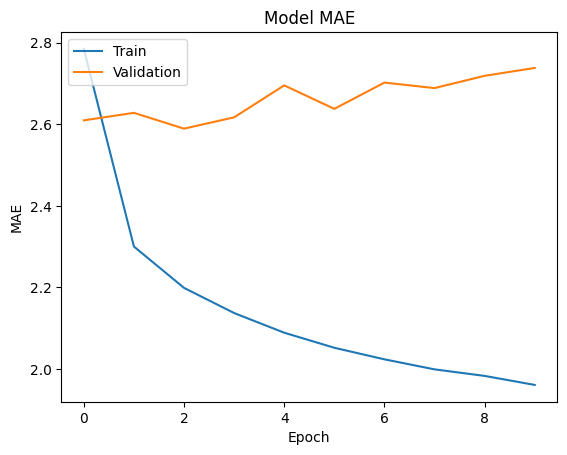

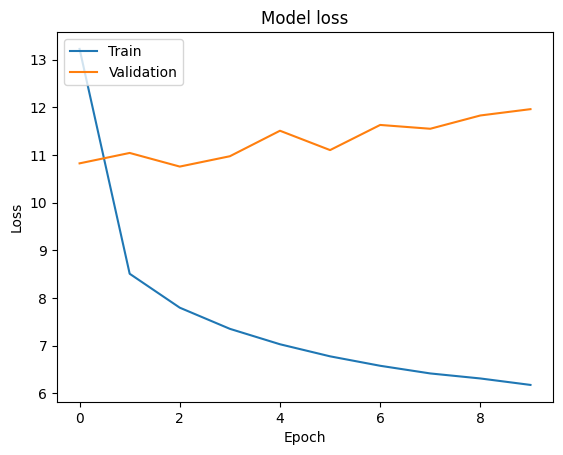

819/819 ━━━━━━━━━━━━━━━━━━━━ 39s 47ms/step - loss: 7.3763 - mae: 2.1420 - rmse: 2.7159
408/408 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - loss: 10.7267 - mae: 2.5845 - rmse: 3.2751
405/405 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - loss: 11.8378 - mae: 2.6937 - rmse: 3.4362
Train      MAE: 2.13, RMSE: 2.70
Validation MAE: 2.59, RMSE: 3.28
Test       MAE: 2.67, RMSE: 3.40
Results:
       Model Name       Details  Train MAE   Val MAE  Test MAE  Train RMSE  \
0        Baseline  Previous day   2.691644  2.441733  2.622036    3.492441   
1  jena_mlp.keras                 2.129634  2.589282  2.672652    2.702645   

   Val RMSE  Test RMSE  Epochs    Time (s)  
0  3.177835   3.426826       0   -1.000000  
1  3.279459   3.397715      10  604.268048  
Results:


,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048


In [14]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_mlp.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_MLP_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset_fl,
                    epochs=max_epochs,
                    validation_data=val_dataset_fl,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset_fl)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset_fl)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset_fl)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

In [15]:
import matplotlib.pyplot as plt

def plot_predictions(dataset, model, num_samples=24, start_index=0):
    """Plots predicted vs. real outputs starting from a specific index."""
    preds_list = []
    targets_list = []

    samples_seen = 0
    total_seen = 0

    for samples, targets in dataset:
        batch_size = samples.shape[0]
        if total_seen + batch_size <= start_index:
            total_seen += batch_size
            continue

        batch_start_index = max(0, start_index - total_seen)

        preds = model.predict(samples, verbose = 0)
        preds_list.extend(preds.reshape(-1)[batch_start_index:])
        targets_list.extend(targets[batch_start_index:])

        samples_seen += batch_size - batch_start_index
        total_seen += batch_size

        if samples_seen >= num_samples:
            break

    # Zkrácení na požadovaný počet vzorků
    preds_list = preds_list[:num_samples]
    targets_list = targets_list[:num_samples]

    plt.figure(figsize=(10, 3))
    plt.plot(targets_list, label='Real Values')
    plt.plot(preds_list, label='Predicted Values')
    plt.xlabel('Sample Index')
    plt.ylabel('Temperature (°C)')
    plt.title('Predicted vs. Real Temperature')
    plt.legend()
    plt.show()


### Observe the results

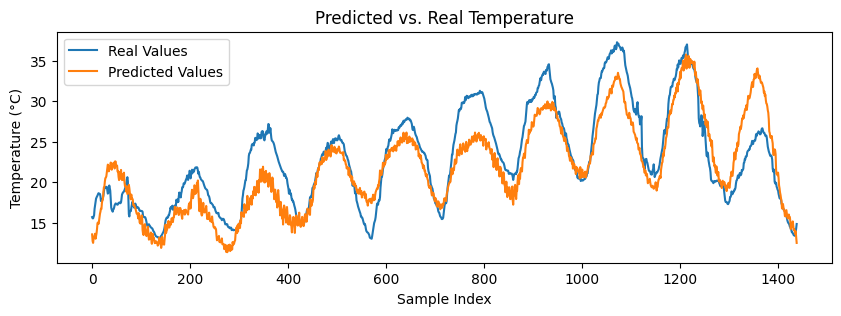

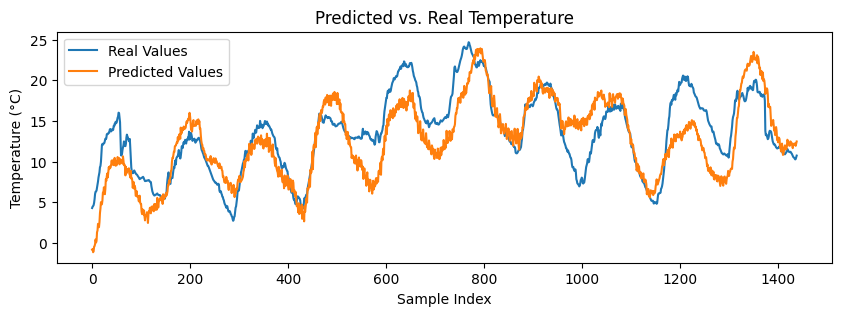

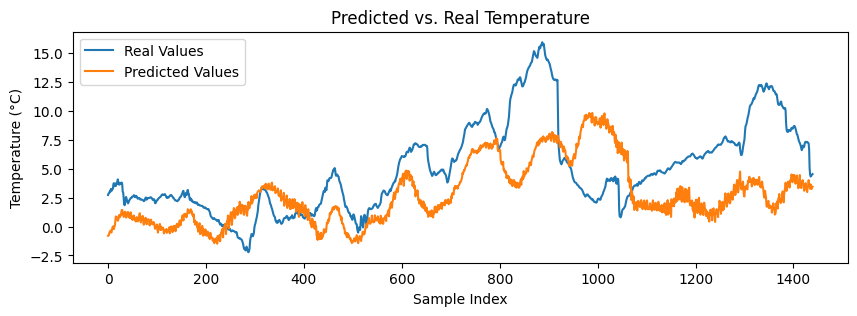

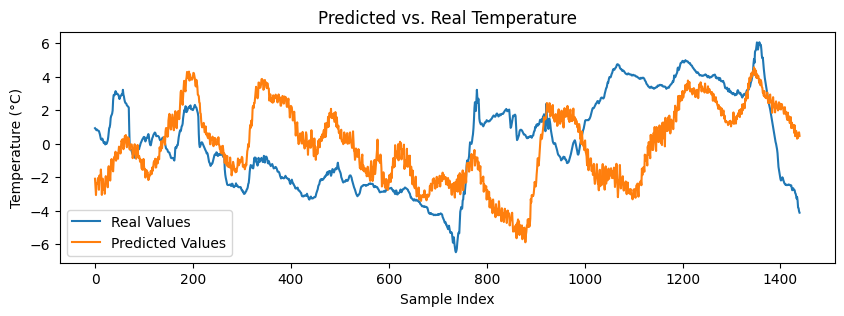

In [16]:
model = keras.models.load_model("models/jena_mlp.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset_fl, model, 24*6*10, start_index)

## 1D CNN Model

### Define the model

In [17]:
import keras
from keras import layers

# Define the model architecture:
def get_CNN_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.Conv1D(filters=8, kernel_size=24, activation="relu")(inputs)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(8, 12, activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(8, 6, activation="relu")(x)

    # Flatten
    x = layers.GlobalAveragePooling1D()(x)

    outputs = layers.Dense(1)(x) # linear output

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model
model = get_CNN_model()
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 97, 8)          │         2,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,873 (15.13 KB)

 Trainable params: 3,873 (15.13 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 91s 108ms/step - loss: 41.5998 - mae: 4.7577 - rmse: 6.2188 - val_loss: 15.2142 - val_mae: 3.0779 - val_rmse: 3.9005
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 90s 110ms/step - loss: 14.0454 - mae: 2.9709 - rmse: 3.7476 - val_loss: 15.4702 - val_mae: 3.0949 - val_rmse: 3.9332
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 142s 109ms/step - loss: 12.6685 - mae: 2.8128 - rmse: 3.5592 - val_loss: 15.2545 - val_mae: 3.0638 - val_rmse: 3.9057
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 92s 112ms/step - loss: 11.8383 - mae: 2.7230 - rmse: 3.4406 - val_loss: 15.5307 - val_mae: 3.0699 - val_rmse: 3.9409
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 93s 114ms/step - loss: 11.2577 - mae: 2.6529 - rmse: 3.3552 - val_loss: 15.4527 - val_mae: 3.0867 - val_rmse: 3.9310
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 89s 109ms/step - loss: 10.7679 - mae: 2.5958 - rmse: 3.2814 - val_loss: 15.9806 - val_mae: 3.1240 - val_rmse: 3.9976
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 96s 117ms/step - 

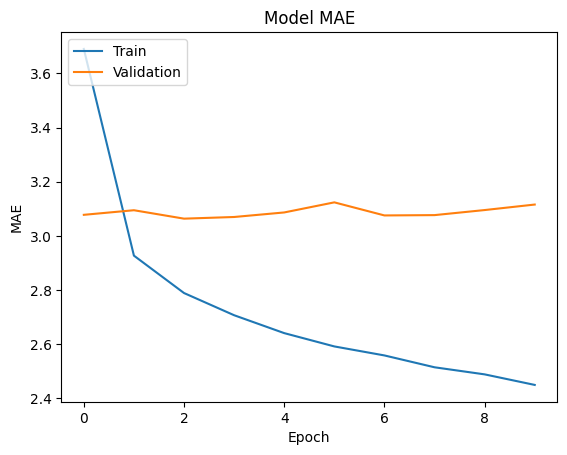

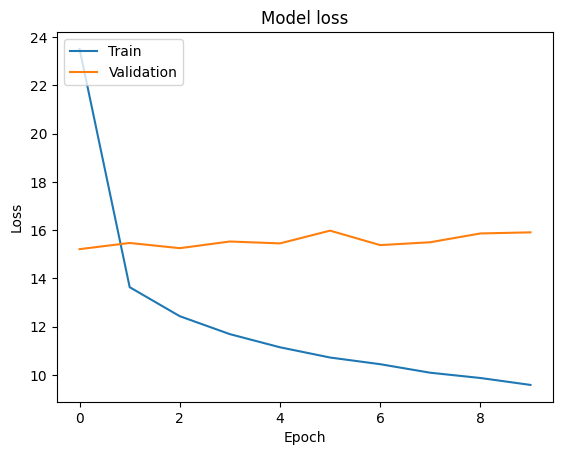

819/819 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - loss: 14.6615 - mae: 3.0254 - rmse: 3.8290
408/408 ━━━━━━━━━━━━━━━━━━━━ 24s 58ms/step - loss: 15.1449 - mae: 3.0739 - rmse: 3.8916
405/405 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - loss: 17.3662 - mae: 3.2793 - rmse: 4.1607
Train      MAE: 3.03, RMSE: 3.83
Validation MAE: 3.08, RMSE: 3.90
Test       MAE: 3.30, RMSE: 4.19
Results:
       Model Name       Details  Train MAE   Val MAE  Test MAE  Train RMSE  \
0        Baseline  Previous day   2.691644  2.441733  2.622036    3.492441   
1  jena_mlp.keras                 2.129634  2.589282  2.672652    2.702645   
2  jena_cnn.keras                 3.027277  3.077919  3.303079    3.827525   

   Val RMSE  Test RMSE  Epochs     Time (s)  
0  3.177835   3.426826       0    -1.000000  
1  3.279459   3.397715      10   604.268048  
2  3.900535   4.189565      10  1017.088803  
Results:


,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803


In [18]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_cnn.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_CNN_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

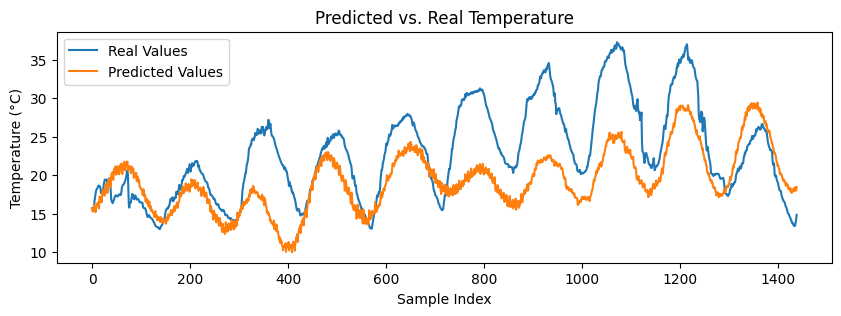

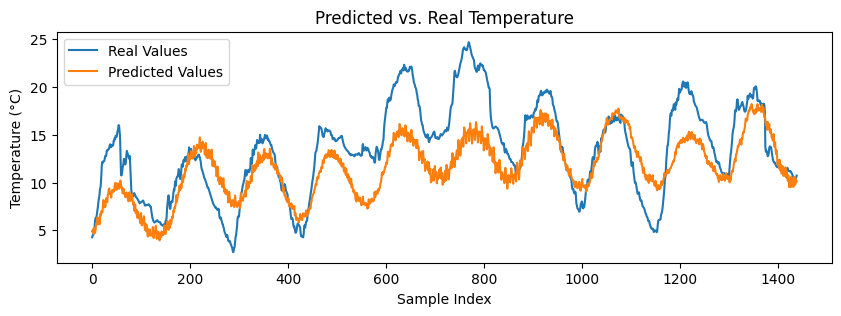

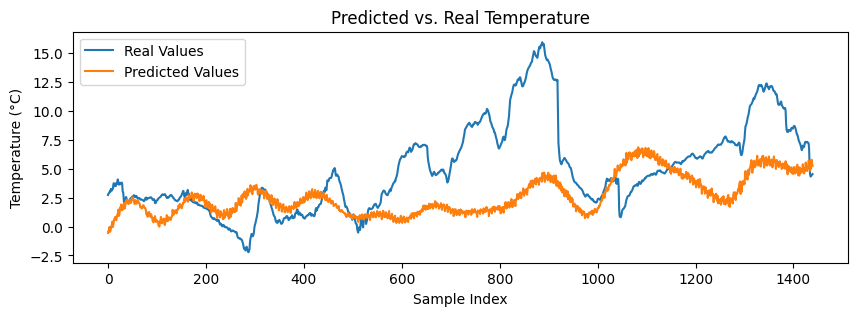

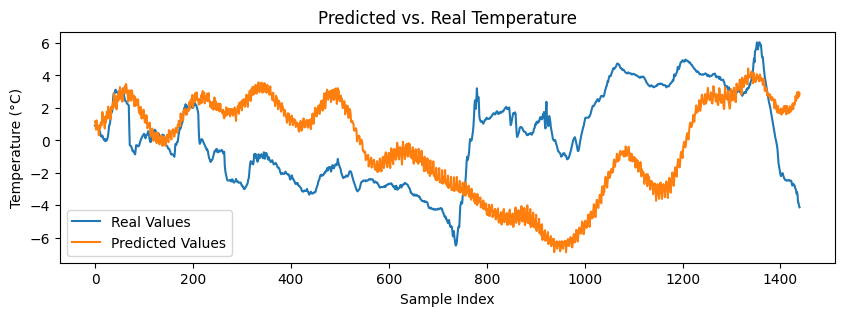

In [19]:
model = keras.models.load_model("models/jena_cnn.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

## A vanilla RNN model

### Define the model

In [20]:
import keras
from keras import layers

def get_SimpleRNN_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.SimpleRNN(16)(inputs)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_SimpleRNN_model()
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 83s 99ms/step - loss: 79.7895 - mae: 6.8996 - rmse: 8.7912 - val_loss: 18.8648 - val_mae: 3.1807 - val_rmse: 4.3434
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 81s 98ms/step - loss: 16.5309 - mae: 3.0535 - rmse: 4.0626 - val_loss: 11.6335 - val_mae: 2.5854 - val_rmse: 3.4108
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 81s 98ms/step - loss: 12.0216 - mae: 2.6832 - rmse: 3.4670 - val_loss: 10.0550 - val_mae: 2.4294 - val_rmse: 3.1710
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - loss: 11.0635 - mae: 2.5895 - rmse: 3.3261 - val_loss: 9.5898 - val_mae: 2.3873 - val_rmse: 3.0967
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 81s 99ms/step - loss: 10.6561 - mae: 2.5430 - rmse: 3.2643 - val_loss: 9.2571 - val_mae: 2.3571 - val_rmse: 3.0425
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 80s 98ms/step - loss: 10.4159 - mae: 2.5147 - rmse: 3.2273 - val_loss: 9.1163 - val_mae: 2.3459 - val_rmse: 3.0193
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - loss: 10.

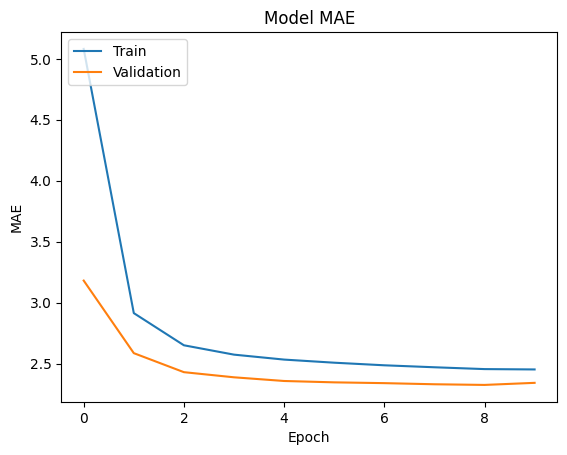

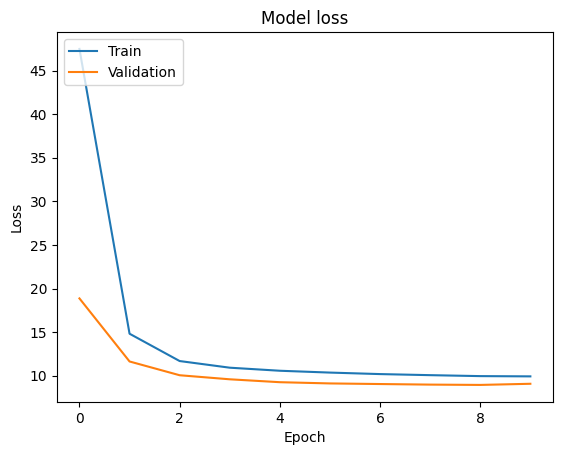

819/819 ━━━━━━━━━━━━━━━━━━━━ 47s 57ms/step - loss: 9.9111 - mae: 2.4535 - rmse: 3.1482
408/408 ━━━━━━━━━━━━━━━━━━━━ 24s 57ms/step - loss: 8.9065 - mae: 2.3164 - rmse: 2.9844
405/405 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - loss: 11.2560 - mae: 2.5747 - rmse: 3.3470
Train      MAE: 2.45, RMSE: 3.14
Validation MAE: 2.32, RMSE: 2.99
Test       MAE: 2.50, RMSE: 3.23
Results:
             Model Name       Details  Train MAE   Val MAE  Test MAE  \
0              Baseline  Previous day   2.691644  2.441733  2.622036   
1        jena_mlp.keras                 2.129634  2.589282  2.672652   
2        jena_cnn.keras                 3.027277  3.077919  3.303079   
3  jena_simpleRNN.keras                 2.448694  2.324813  2.502647   

   Train RMSE  Val RMSE  Test RMSE  Epochs     Time (s)  
0    3.492441  3.177835   3.426826       0    -1.000000  
1    2.702645  3.279459   3.397715      10   604.268048  
2    3.827525  3.900535   4.189565      10  1017.088803  
3    3.144267  2.990824   3.226822   

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491


In [21]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_simpleRNN.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_SimpleRNN_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

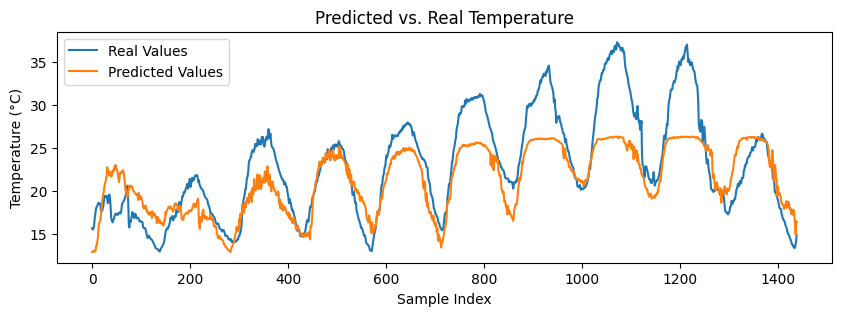

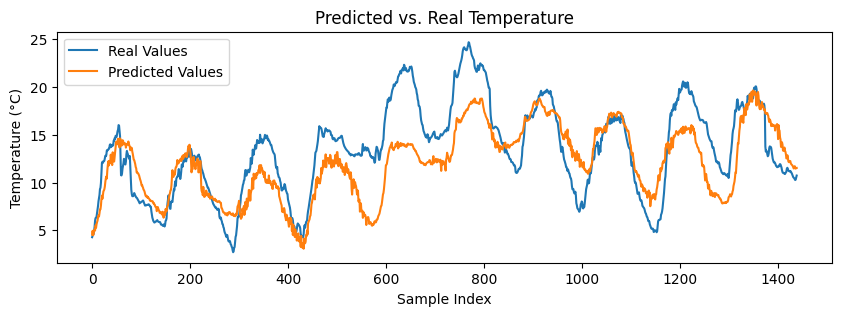

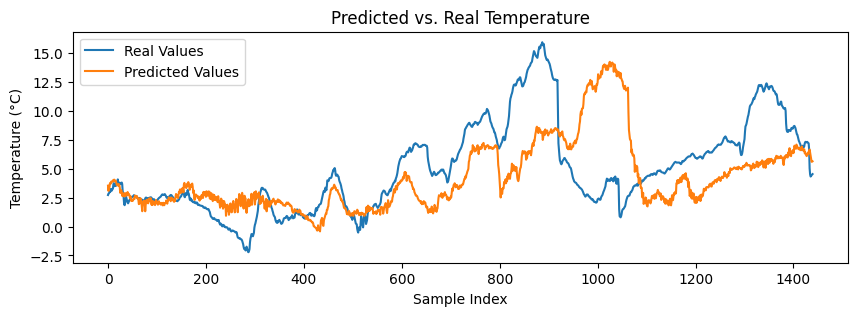

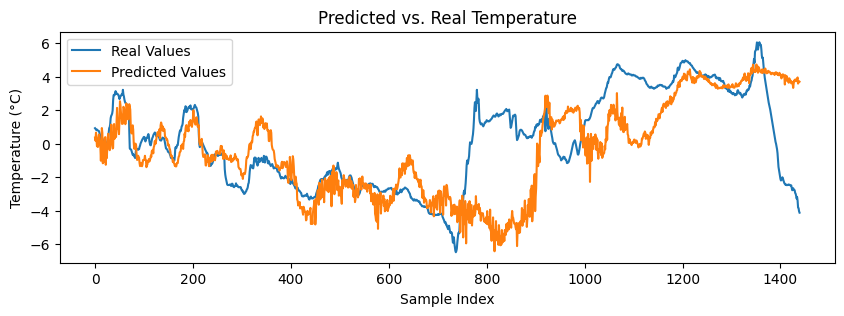

In [22]:
model = keras.models.load_model("models/jena_simpleRNN.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

In [34]:
results_df

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491


In [33]:
#results_df = results_df.drop(4, axis=0).reset_index(drop=True)

## LSTM

#### Define the model

In [35]:
import keras
from keras import layers

def get_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.LSTM(16)(inputs)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_LSTM_model()
model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 116s 138ms/step - loss: 75.5360 - mae: 6.6724 - rmse: 8.5277 - val_loss: 16.4444 - val_mae: 3.0267 - val_rmse: 4.0552
Epoch 2/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 115s 140ms/step - loss: 15.8592 - mae: 3.0171 - rmse: 3.9801 - val_loss: 11.2220 - val_mae: 2.5746 - val_rmse: 3.3499
Epoch 3/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 115s 140ms/step - loss: 11.6884 - mae: 2.6505 - rmse: 3.4186 - val_loss: 9.9673 - val_mae: 2.4502 - val_rmse: 3.1571
Epoch 4/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 115s 140ms/step - loss: 10.6378 - mae: 2.5378 - rmse: 3.2615 - val_loss: 9.6485 - val_mae: 2.4158 - val_rmse: 3.1062
Epoch 5/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 142s 140ms/step - loss: 10.0926 - mae: 2.4737 - rmse: 3.1769 - val_loss: 9.6089 - val_mae: 2.4082 - val_rmse: 3.0998
Epoch 6/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 114s 139ms/step - loss: 9.7684 - mae: 2.4346 - rmse: 3.1254 - val_loss: 9.6839 - val_mae: 2.4178 - val_rmse: 3.1119
Epoch 7/14
819/819 ━━━━━━━━━━━━━━━━━━━━ 113s 137ms/step -

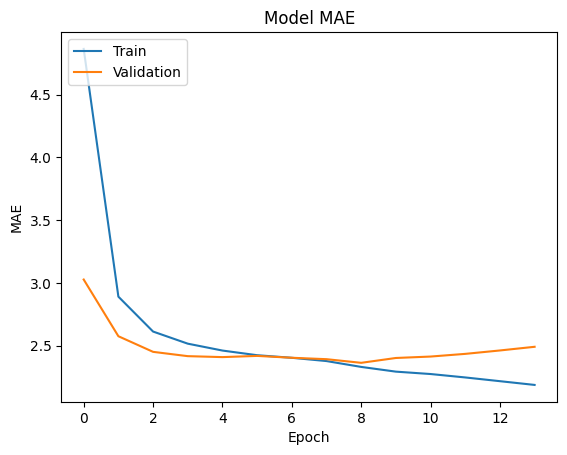

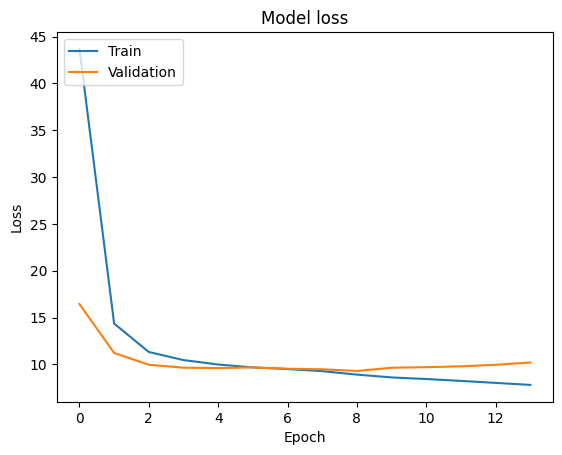

819/819 ━━━━━━━━━━━━━━━━━━━━ 63s 75ms/step - loss: 8.8311 - mae: 2.3234 - rmse: 2.9717
408/408 ━━━━━━━━━━━━━━━━━━━━ 30s 72ms/step - loss: 9.2609 - mae: 2.3547 - rmse: 3.0431
405/405 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - loss: 12.8048 - mae: 2.7649 - rmse: 3.5716
Train      MAE: 2.32, RMSE: 2.97
Validation MAE: 2.36, RMSE: 3.05
Test       MAE: 2.62, RMSE: 3.39
Results:
             Model Name       Details  Train MAE   Val MAE  Test MAE  \
0              Baseline  Previous day   2.691644  2.441733  2.622036   
1        jena_mlp.keras                 2.129634  2.589282  2.672652   
2        jena_cnn.keras                 3.027277  3.077919  3.303079   
3  jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4       jena_lstm.keras                 2.317899  2.362597  2.615515   

   Train RMSE  Val RMSE  Test RMSE  Epochs     Time (s)  
0    3.492441  3.177835   3.426826       0    -1.000000  
1    2.702645  3.279459   3.397715      10   604.268048  
2    3.827525  3.900535

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876


In [36]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 14 # change !!!
model_name = "jena_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_LSTM_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

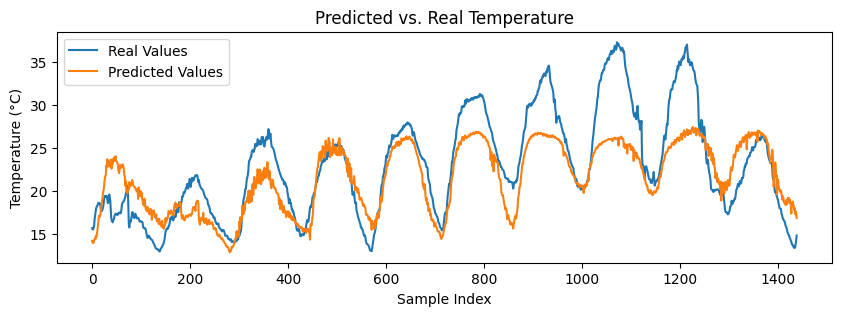

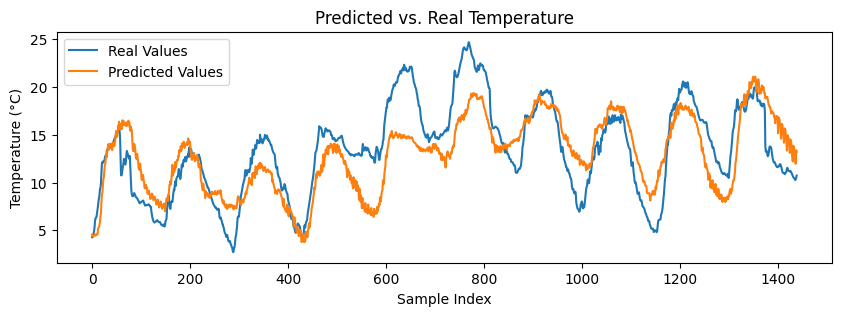

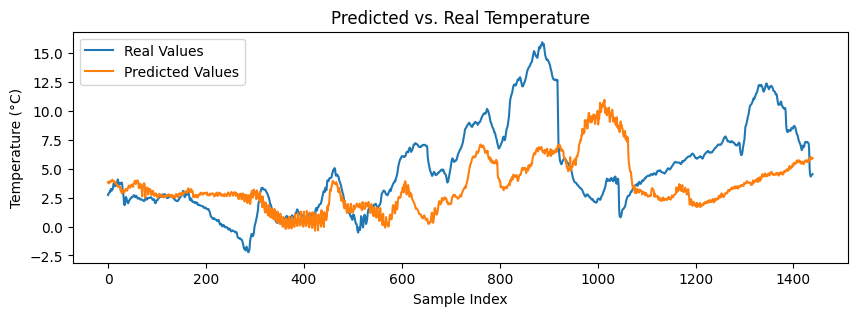

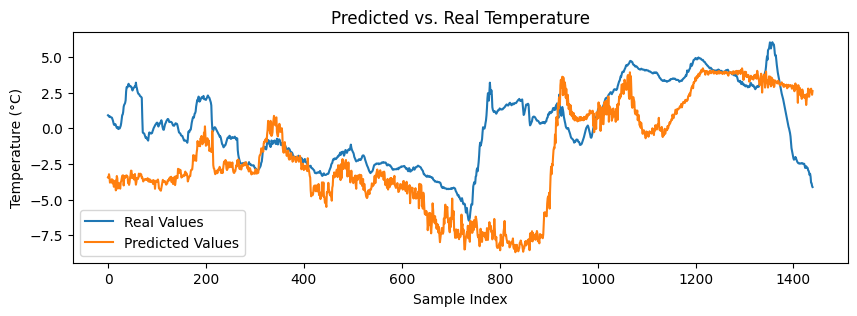

In [37]:
model = keras.models.load_model("models/jena_lstm.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

## GRU

### Define the model

In [38]:
import keras
from keras import layers

def get_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16)(inputs) # change

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_GRU_model()
model.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 16)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,553 (6.07 KB)

 Trainable params: 1,553 (6.07 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 138s 166ms/step - loss: 67.1389 - mae: 6.3302 - rmse: 8.0527 - val_loss: 16.7522 - val_mae: 3.0279 - val_rmse: 4.0929
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 139s 169ms/step - loss: 14.5726 - mae: 2.8918 - rmse: 3.8154 - val_loss: 11.3640 - val_mae: 2.5519 - val_rmse: 3.3711
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 139s 165ms/step - loss: 10.8564 - mae: 2.5546 - rmse: 3.2947 - val_loss: 10.4219 - val_mae: 2.4585 - val_rmse: 3.2283
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 139s 169ms/step - loss: 9.8149 - mae: 2.4426 - rmse: 3.1328 - val_loss: 10.1062 - val_mae: 2.4291 - val_rmse: 3.1790
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 139s 169ms/step - loss: 9.3386 - mae: 2.3851 - rmse: 3.0559 - val_loss: 10.0999 - val_mae: 2.4248 - val_rmse: 3.1780
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 135s 165ms/step - loss: 9.0413 - mae: 2.3500 - rmse: 3.0068 - val_loss: 10.5212 - val_mae: 2.4613 - val_rmse: 3.2436
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 137s 167ms/step

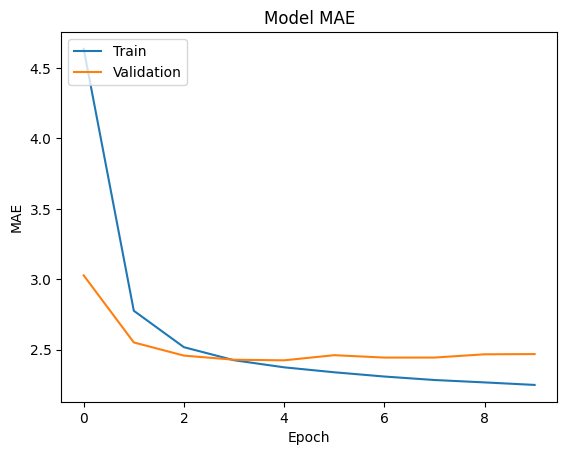

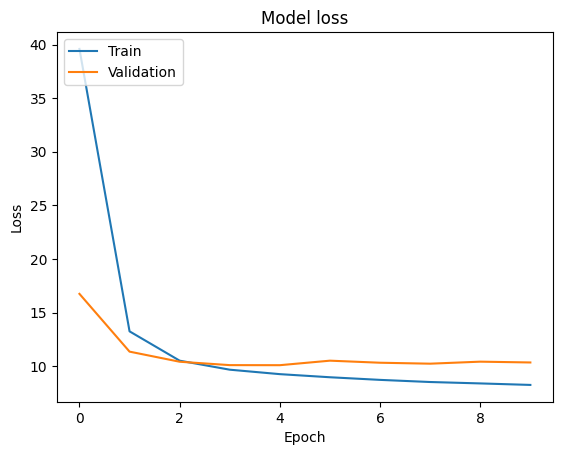

819/819 ━━━━━━━━━━━━━━━━━━━━ 59s 72ms/step - loss: 9.0606 - mae: 2.3523 - rmse: 3.0100
408/408 ━━━━━━━━━━━━━━━━━━━━ 32s 76ms/step - loss: 10.1040 - mae: 2.4229 - rmse: 3.1787
405/405 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - loss: 10.9439 - mae: 2.5751 - rmse: 3.3018
Train      MAE: 2.35, RMSE: 3.01
Validation MAE: 2.42, RMSE: 3.18
Test       MAE: 2.51, RMSE: 3.19
Results:
             Model Name       Details  Train MAE   Val MAE  Test MAE  \
0              Baseline  Previous day   2.691644  2.441733  2.622036   
1        jena_mlp.keras                 2.129634  2.589282  2.672652   
2        jena_cnn.keras                 3.027277  3.077919  3.303079   
3  jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4       jena_lstm.keras                 2.317899  2.362597  2.615515   
5        jena_gru.keras                 2.351283  2.424803  2.506056   

   Train RMSE  Val RMSE  Test RMSE  Epochs     Time (s)  
0    3.492441  3.177835   3.426826       0    -1.000000  
1    2.7

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566


In [39]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10
model_name = "jena_gru.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(), # SGD, Adam, RMSProp
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

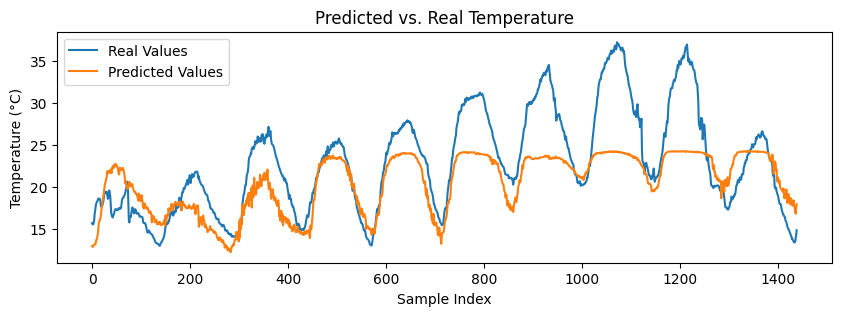

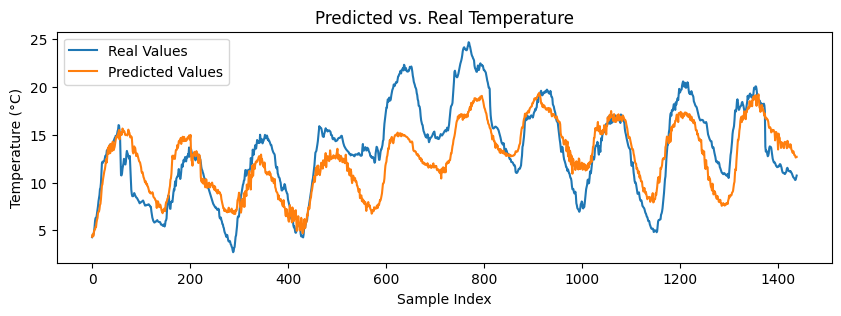

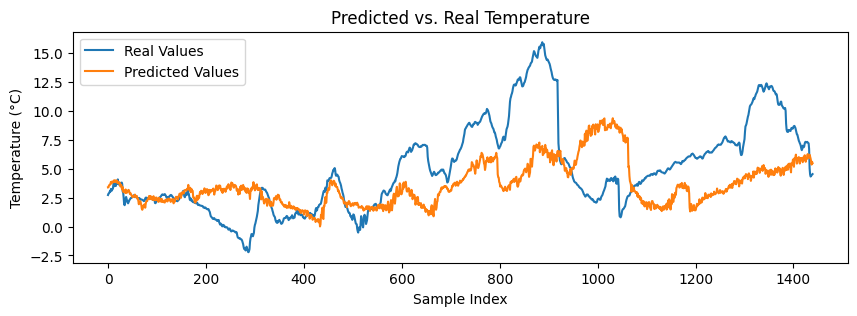

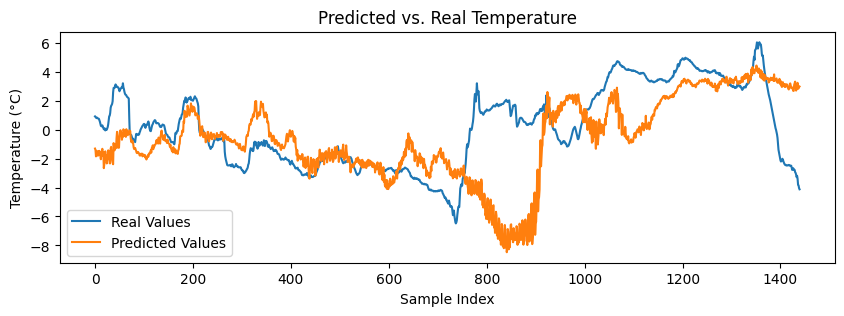

In [40]:
model = keras.models.load_model("models/jena_gru.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

## LSTM with dropout and gradient clipping

### Define the model

In [41]:
import keras
from keras import layers

def get_regularized_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
    x = layers.LSTM(32, recurrent_dropout=0.25)(inputs) # change 16 -> 32.
    x = layers.Dropout(0.5)(x)                          # dropout
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_regularized_LSTM_model()
model.summary()

# optimizer= keras.optimizers.Adam(clipnorm=1.0)

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 187s 220ms/step - loss: 55.5481 - mae: 5.5282 - rmse: 7.2416 - val_loss: 9.6583 - val_mae: 2.4076 - val_rmse: 3.1078
Epoch 2/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 182s 222ms/step - loss: 15.3833 - mae: 3.0476 - rmse: 3.9221 - val_loss: 9.2259 - val_mae: 2.3639 - val_rmse: 3.0374
Epoch 3/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 183s 223ms/step - loss: 14.5459 - mae: 2.9584 - rmse: 3.8139 - val_loss: 9.1100 - val_mae: 2.3464 - val_rmse: 3.0183
Epoch 4/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 184s 225ms/step - loss: 14.0400 - mae: 2.9102 - rmse: 3.7470 - val_loss: 9.0832 - val_mae: 2.3361 - val_rmse: 3.0138
Epoch 5/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 183s 223ms/step - loss: 13.6560 - mae: 2.8744 - rmse: 3.6954 - val_loss: 9.1062 - val_mae: 2.3344 - val_rmse: 3.0176
Epoch 6/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 200s 220ms/step - loss: 13.3257 - mae: 2.8340 - rmse: 3.6504 - val_loss: 9.0376 - val_mae: 2.3284 - val_rmse: 3.0063
Epoch 7/30
819/819 ━━━━━━━━━━━━━━━━━━━━ 184s 225ms/step - 

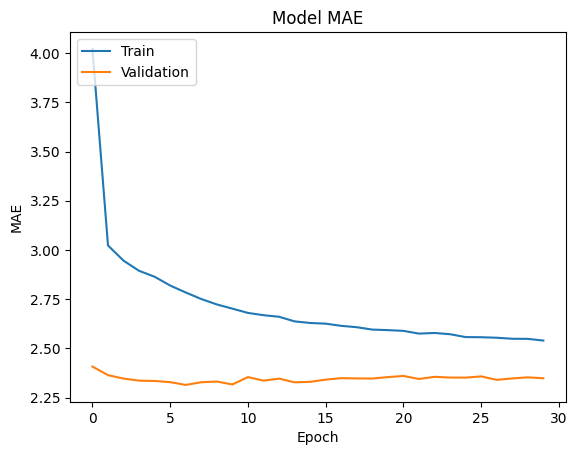

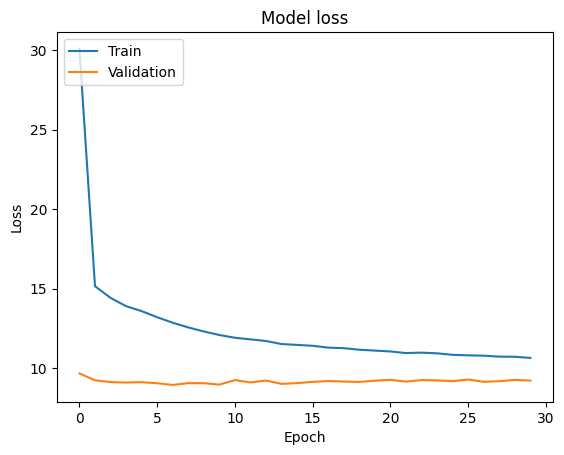

819/819 ━━━━━━━━━━━━━━━━━━━━ 73s 88ms/step - loss: 8.9696 - mae: 2.3419 - rmse: 2.9949
408/408 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - loss: 8.8850 - mae: 2.3051 - rmse: 2.9808
405/405 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step - loss: 10.8700 - mae: 2.5700 - rmse: 3.2903
Train      MAE: 2.34, RMSE: 2.99
Validation MAE: 2.31, RMSE: 2.99
Test       MAE: 2.50, RMSE: 3.17
Results:
             Model Name       Details  Train MAE   Val MAE  Test MAE  \
0              Baseline  Previous day   2.691644  2.441733  2.622036   
1        jena_mlp.keras                 2.129634  2.589282  2.672652   
2        jena_cnn.keras                 3.027277  3.077919  3.303079   
3  jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4       jena_lstm.keras                 2.317899  2.362597  2.615515   
5        jena_gru.keras                 2.351283  2.424803  2.506056   
6   jena_reg_lstm.keras                 2.337568  2.314306  2.495306   

   Train RMSE  Val RMSE  Test RMSE  Epochs     Time (

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566
6,jena_reg_lstm.keras,,2.337568,2.314306,2.495306,2.991771,2.988857,3.172751,30,5537.813763


In [42]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 30      # change !!!!!!!!!
model_name = "jena_reg_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_regularized_LSTM_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

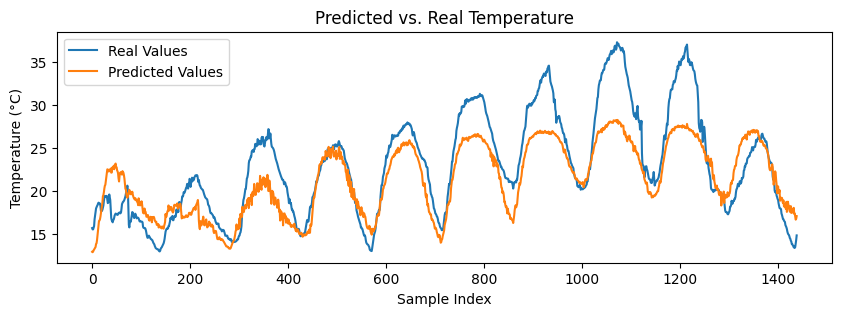

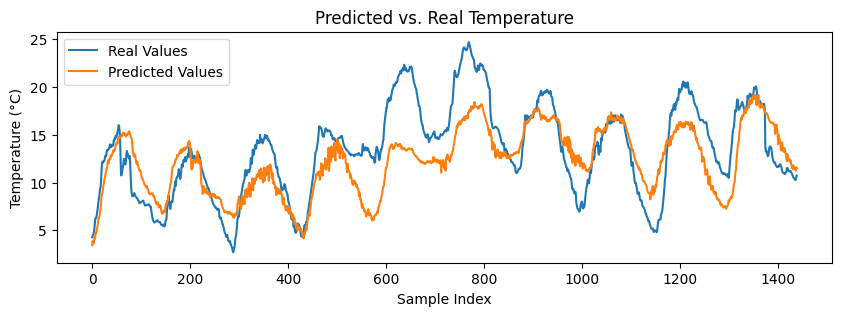

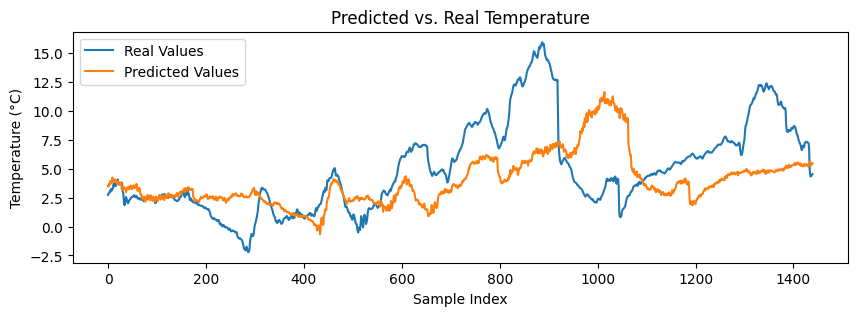

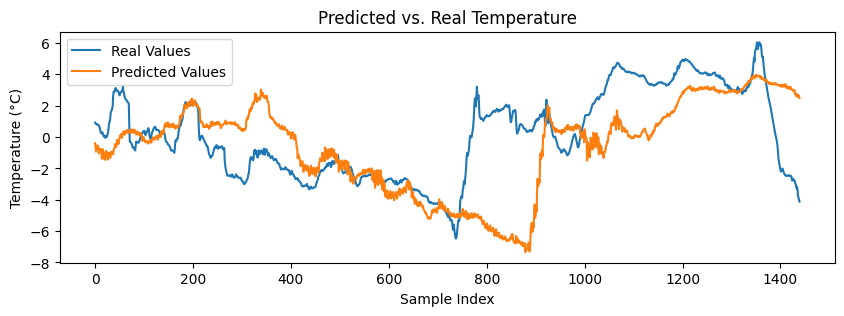

In [43]:
model = keras.models.load_model("models/jena_reg_lstm.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

In [44]:
print(results_df)

             Model Name       Details  Train MAE   Val MAE  Test MAE  \
0              Baseline  Previous day   2.691644  2.441733  2.622036   
1        jena_mlp.keras                 2.129634  2.589282  2.672652   
2        jena_cnn.keras                 3.027277  3.077919  3.303079   
3  jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4       jena_lstm.keras                 2.317899  2.362597  2.615515   
5        jena_gru.keras                 2.351283  2.424803  2.506056   
6   jena_reg_lstm.keras                 2.337568  2.314306  2.495306   

   Train RMSE  Val RMSE  Test RMSE  Epochs     Time (s)  
0    3.492441  3.177835   3.426826       0    -1.000000  
1    2.702645  3.279459   3.397715      10   604.268048  
2    3.827525  3.900535   4.189565      10  1017.088803  
3    3.144267  2.990824   3.226822      10   816.164491  
4    2.965745  3.049811   3.386308      14  1663.462876  
5    3.010933  3.178030   3.193945      10  1378.518566  
6    2.991771  2.

In [45]:
#results_df = results_df.drop(6, axis=0).reset_index(drop=True)

## GRU with more layers

### Define the model

In [46]:
import keras
from keras import layers

def get_layered_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16, return_sequences=True)(inputs)

    x = layers.GRU(16)(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_layered_GRU_model()
model.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ (None, 120, 16)        │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_5 (GRU)                     │ (None, 16)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,185 (12.44 KB)

 Trainable params: 3,185 (12.44 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 224s 267ms/step - loss: 68.9971 - mae: 6.3048 - rmse: 8.1711 - val_loss: 11.8689 - val_mae: 2.5778 - val_rmse: 3.4451
Epoch 2/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 220s 268ms/step - loss: 13.6999 - mae: 2.8505 - rmse: 3.7006 - val_loss: 9.2163 - val_mae: 2.3361 - val_rmse: 3.0358
Epoch 3/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 217s 265ms/step - loss: 12.0732 - mae: 2.6929 - rmse: 3.4746 - val_loss: 9.1692 - val_mae: 2.3334 - val_rmse: 3.0281
Epoch 4/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 222s 271ms/step - loss: 11.5109 - mae: 2.6388 - rmse: 3.3927 - val_loss: 8.8341 - val_mae: 2.2978 - val_rmse: 2.9722
Epoch 5/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 217s 264ms/step - loss: 10.9927 - mae: 2.5791 - rmse: 3.3155 - val_loss: 8.9060 - val_mae: 2.3003 - val_rmse: 2.9843
Epoch 6/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 220s 268ms/step - loss: 10.6038 - mae: 2.5337 - rmse: 3.2563 - val_loss: 8.8730 - val_mae: 2.3107 - val_rmse: 2.9788
Epoch 7/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 220s 269ms/step -

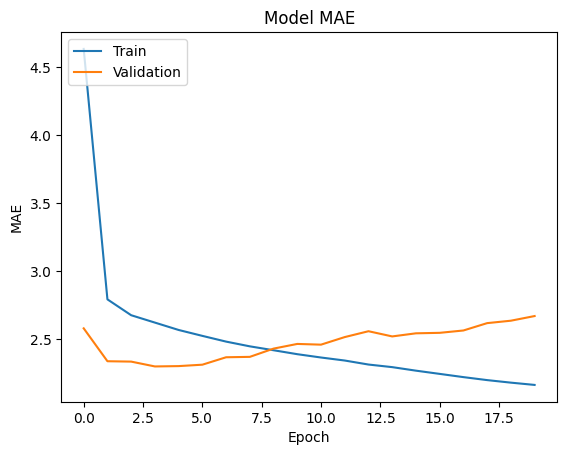

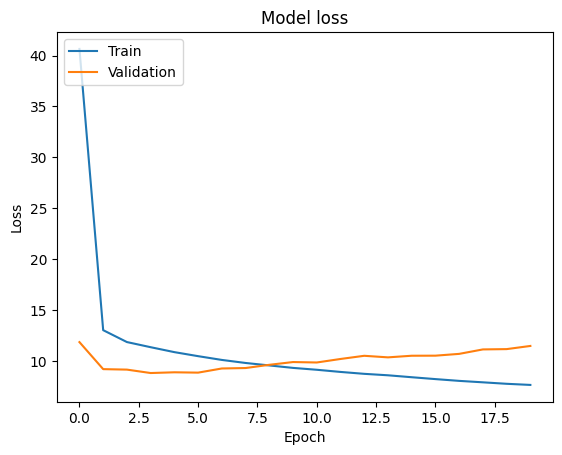

819/819 ━━━━━━━━━━━━━━━━━━━━ 74s 89ms/step - loss: 8.6361 - mae: 2.3011 - rmse: 2.9387
408/408 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 8.8034 - mae: 2.2927 - rmse: 2.9670
405/405 ━━━━━━━━━━━━━━━━━━━━ 38s 94ms/step - loss: 10.9393 - mae: 2.5688 - rmse: 3.3025
Train      MAE: 2.30, RMSE: 2.94
Validation MAE: 2.30, RMSE: 2.97
Test       MAE: 2.50, RMSE: 3.19
Results:
               Model Name       Details  Train MAE   Val MAE  Test MAE  \
0                Baseline  Previous day   2.691644  2.441733  2.622036   
1          jena_mlp.keras                 2.129634  2.589282  2.672652   
2          jena_cnn.keras                 3.027277  3.077919  3.303079   
3    jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4         jena_lstm.keras                 2.317899  2.362597  2.615515   
5          jena_gru.keras                 2.351283  2.424803  2.506056   
6     jena_reg_lstm.keras                 2.337568  2.314306  2.495306   
7  jena_layered_gru.keras             

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566
6,jena_reg_lstm.keras,,2.337568,2.314306,2.495306,2.991771,2.988857,3.172751,30,5537.813763
7,jena_layered_gru.keras,,2.300835,2.297789,2.496914,2.937477,2.972229,3.190335,20,4436.961320


In [47]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 20      # change !!!!!!!!!
model_name = "jena_layered_gru.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layered_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

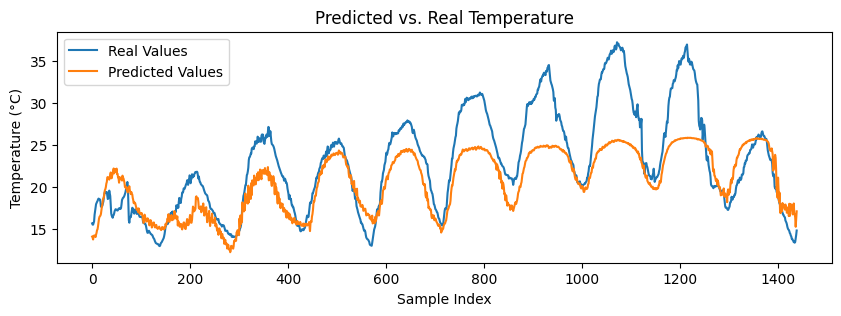

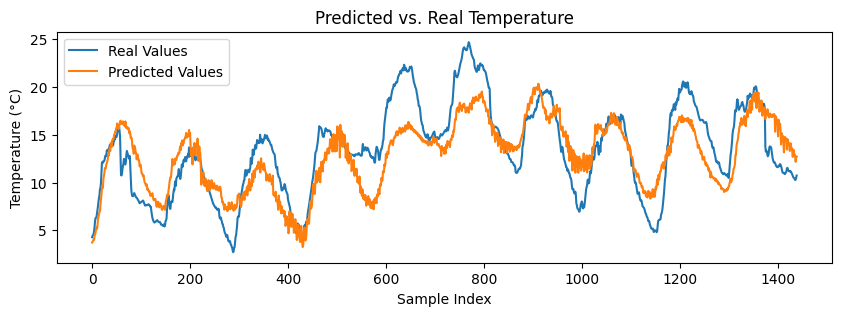

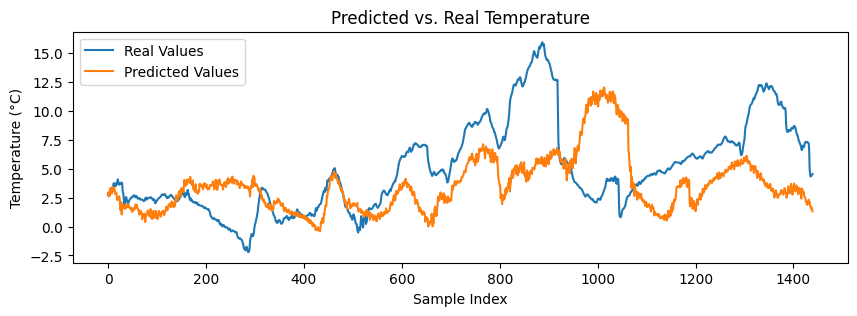

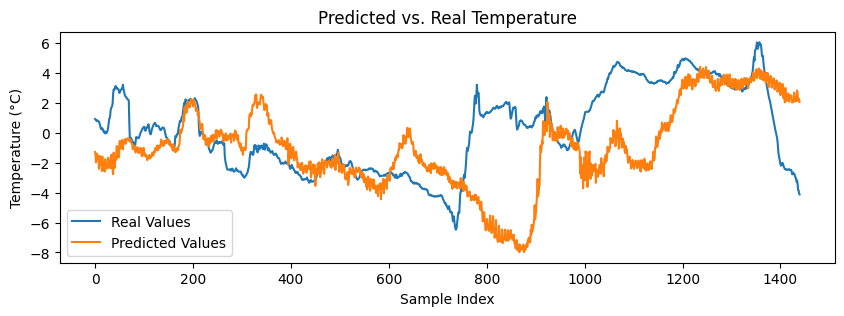

In [48]:
model = keras.models.load_model("models/jena_layered_gru.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

## Layer normalized model

### Define the model

In [49]:
import keras
from keras import layers

def get_layer_norm_GRU_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

    x = layers.GRU(16, return_sequences=True)(inputs)
    x = layers.LayerNormalization()(x)

    x = layers.GRU(16)(x)
    x = layers.LayerNormalization()(x)

    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model
model = get_layer_norm_GRU_model()
model.summary()



Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_8 (GRU)                     │ (None, 120, 16)        │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 120, 16)        │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_9 (GRU)                     │ (None, 16)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 16)             │            32 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,249 (12.69 KB)

 Trainable params: 3,249 (12.69 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 240s 281ms/step - loss: 48.5982 - mae: 5.0745 - rmse: 6.7577 - val_loss: 9.2581 - val_mae: 2.3699 - val_rmse: 3.0427
Epoch 2/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 234s 285ms/step - loss: 9.5097 - mae: 2.4084 - rmse: 3.0835 - val_loss: 8.5787 - val_mae: 2.2719 - val_rmse: 2.9289
Epoch 3/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 233s 284ms/step - loss: 8.4793 - mae: 2.2831 - rmse: 2.9119 - val_loss: 9.0964 - val_mae: 2.3454 - val_rmse: 3.0160
Epoch 4/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 232s 283ms/step - loss: 8.0335 - mae: 2.2242 - rmse: 2.8343 - val_loss: 9.2871 - val_mae: 2.3689 - val_rmse: 3.0475
Epoch 5/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 230s 280ms/step - loss: 7.6483 - mae: 2.1727 - rmse: 2.7655 - val_loss: 9.6350 - val_mae: 2.4069 - val_rmse: 3.1040
Epoch 6/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 233s 284ms/step - loss: 7.2966 - mae: 2.1206 - rmse: 2.7011 - val_loss: 9.9758 - val_mae: 2.4528 - val_rmse: 3.1585
Epoch 7/20
819/819 ━━━━━━━━━━━━━━━━━━━━ 262s 284ms/step - loss:

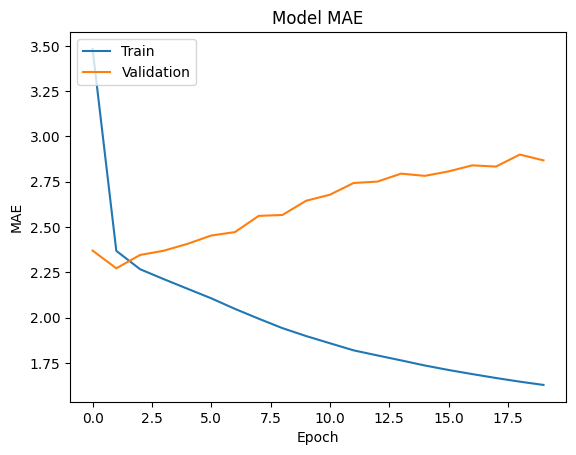

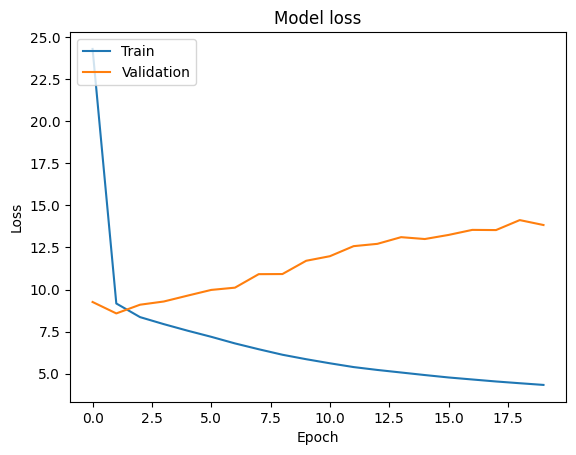

819/819 ━━━━━━━━━━━━━━━━━━━━ 80s 95ms/step - loss: 8.6066 - mae: 2.2950 - rmse: 2.9337
408/408 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - loss: 8.5661 - mae: 2.2687 - rmse: 2.9268
405/405 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 10.1977 - mae: 2.4818 - rmse: 3.1871
Train      MAE: 2.29, RMSE: 2.93
Validation MAE: 2.27, RMSE: 2.93
Test       MAE: 2.42, RMSE: 3.08
Results:
                  Model Name       Details  Train MAE   Val MAE  Test MAE  \
0                   Baseline  Previous day   2.691644  2.441733  2.622036   
1             jena_mlp.keras                 2.129634  2.589282  2.672652   
2             jena_cnn.keras                 3.027277  3.077919  3.303079   
3       jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4            jena_lstm.keras                 2.317899  2.362597  2.615515   
5             jena_gru.keras                 2.351283  2.424803  2.506056   
6        jena_reg_lstm.keras                 2.337568  2.314306  2.495306   
7     jena_la

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566
6,jena_reg_lstm.keras,,2.337568,2.314306,2.495306,2.991771,2.988857,3.172751,30,5537.813763
7,jena_layered_gru.keras,,2.300835,2.297789,2.496914,2.937477,2.972229,3.190335,20,4436.961320
8,jena_layer_norm_GRU.keras,,2.292595,2.271889,2.419856,2.931269,2.928936,3.081884,20,4831.872897


In [50]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 20      # change !!!!!!!!!
model_name = "jena_layer_norm_GRU.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layer_norm_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

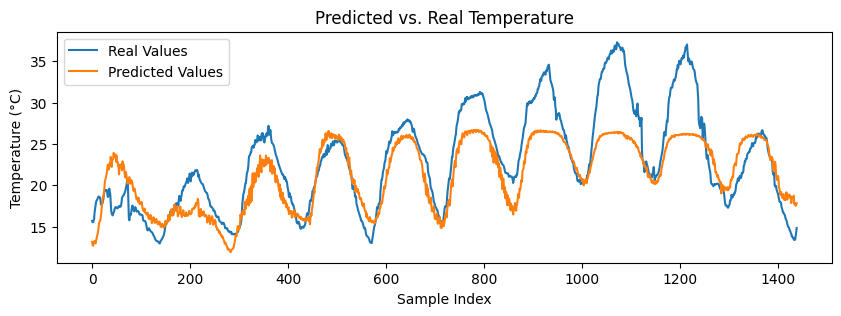

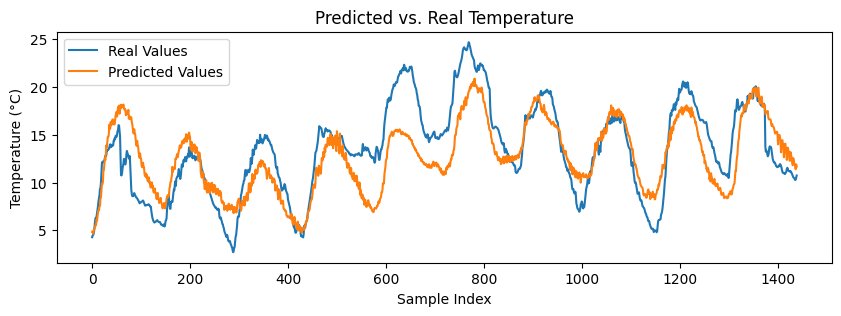

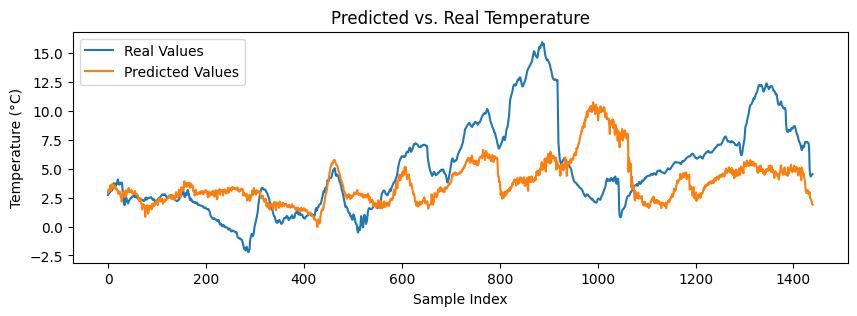

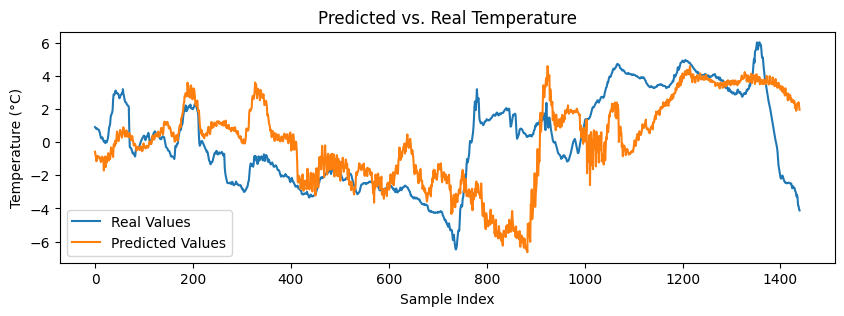

In [51]:
model = keras.models.load_model("models/jena_layer_norm_GRU.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

## Bidirectional RNN

### Define the model

In [52]:
import keras
from keras import layers

def get_bi_LSTM_model():
    inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))
    x = layers.Bidirectional(layers.LSTM(16))(inputs)
    outputs = layers.Dense(1)(x)
    model = keras.Model(inputs, outputs)
    return model

model = get_bi_LSTM_model()
model.summary()

# optimizer= keras.optimizers.Adam(clipnorm=1.0)

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_20 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32)             │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,001 (15.63 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

Epoch 1/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 223s 267ms/step - loss: 67.6982 - mae: 6.2144 - rmse: 8.0780 - val_loss: 11.3271 - val_mae: 2.5293 - val_rmse: 3.3656
Epoch 2/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 259s 263ms/step - loss: 13.6820 - mae: 2.8544 - rmse: 3.6985 - val_loss: 9.3959 - val_mae: 2.3676 - val_rmse: 3.0653
Epoch 3/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 218s 266ms/step - loss: 12.3164 - mae: 2.7199 - rmse: 3.5094 - val_loss: 9.2198 - val_mae: 2.3554 - val_rmse: 3.0364
Epoch 4/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 261s 265ms/step - loss: 11.7278 - mae: 2.6565 - rmse: 3.4246 - val_loss: 8.8722 - val_mae: 2.3062 - val_rmse: 2.9786
Epoch 5/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 265s 269ms/step - loss: 11.2621 - mae: 2.6084 - rmse: 3.3558 - val_loss: 9.0349 - val_mae: 2.3330 - val_rmse: 3.0058
Epoch 6/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 222s 270ms/step - loss: 10.8508 - mae: 2.5601 - rmse: 3.2940 - val_loss: 8.7602 - val_mae: 2.3021 - val_rmse: 2.9598
Epoch 7/10
819/819 ━━━━━━━━━━━━━━━━━━━━ 218s 265ms/step -

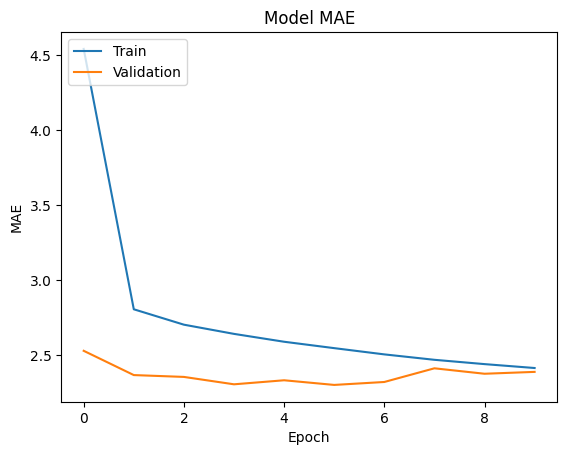

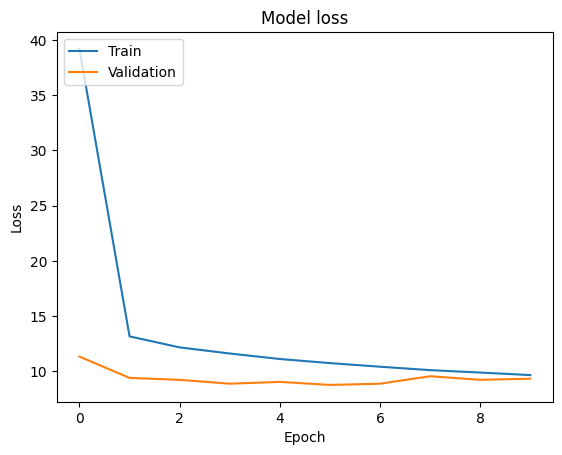

819/819 ━━━━━━━━━━━━━━━━━━━━ 76s 92ms/step - loss: 8.2889 - mae: 2.2472 - rmse: 2.8790
408/408 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 8.7523 - mae: 2.3007 - rmse: 2.9584
405/405 ━━━━━━━━━━━━━━━━━━━━ 37s 90ms/step - loss: 10.6403 - mae: 2.5330 - rmse: 3.2551
Train      MAE: 2.24, RMSE: 2.87
Validation MAE: 2.30, RMSE: 2.96
Test       MAE: 2.44, RMSE: 3.12
Results:
                  Model Name       Details  Train MAE   Val MAE  Test MAE  \
0                   Baseline  Previous day   2.691644  2.441733  2.622036   
1             jena_mlp.keras                 2.129634  2.589282  2.672652   
2             jena_cnn.keras                 3.027277  3.077919  3.303079   
3       jena_simpleRNN.keras                 2.448694  2.324813  2.502647   
4            jena_lstm.keras                 2.317899  2.362597  2.615515   
5             jena_gru.keras                 2.351283  2.424803  2.506056   
6        jena_reg_lstm.keras                 2.337568  2.314306  2.495306   
7     jena_lay

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566
6,jena_reg_lstm.keras,,2.337568,2.314306,2.495306,2.991771,2.988857,3.172751,30,5537.813763
7,jena_layered_gru.keras,,2.300835,2.297789,2.496914,2.937477,2.972229,3.190335,20,4436.961320
8,jena_layer_norm_GRU.keras,,2.292595,2.271889,2.419856,2.931269,2.928936,3.081884,20,4831.872897
9,jena_bi_lstm.keras,,2.242610,2.302074,2.438604,2.873965,2.959759,3.120723,10,2366.750035


In [53]:
# Set some of the hyperparameters:
do_early_stopping = False
do_checkpoint = True
do_tensorboard = True
max_epochs = 10      # change !!!!!!!!!
model_name = "jena_bi_lstm.keras"
details = "" # your comment

###############################################
# Define the model architecture:
model = get_layered_GRU_model()

# Configure the model:
model.compile(optimizer= keras.optimizers.Adam(clipnorm=1.0),  # change !!!!!!
              loss= keras.losses.MeanSquaredError(),
              metrics= [keras.metrics.MeanAbsoluteError(name="mae"), keras.metrics.RootMeanSquaredError(name="rmse")])

# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_jena/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset,
                    epochs=max_epochs,
                    validation_data=val_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)


# Evaluate the model on the training, validation and test sets
train_loss, train_mae, train_rmse = model.evaluate(train_dataset)
val_loss, val_mae, val_rmse = model.evaluate(val_dataset)
test_loss, test_mae, test_rmse = model.evaluate(test_dataset)

print(f"Train      MAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}")
print(f"Validation MAE: {val_mae:.2f}, RMSE: {val_rmse:.2f}")
print(f"Test       MAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}")

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
new_entry = {
    "Model Name" : model_name,
    "Details" : details,
    "Train MAE" : train_mae,
    "Val MAE" : val_mae,
    "Test MAE" : test_mae,
    "Train RMSE" : train_rmse,
    "Val RMSE" : val_rmse,
    "Test RMSE" : test_rmse,
    "Epochs": max_epochs,
    "Time (s)": time_fit,
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
print("Results:")
print(results_df)
results_df.to_csv("models/jena_results.csv", index=False)

# View and and save the dataframe:
results_df.to_csv("models/jena_results.csv", index=False)
print("Results:")
results_df

### Observe the results

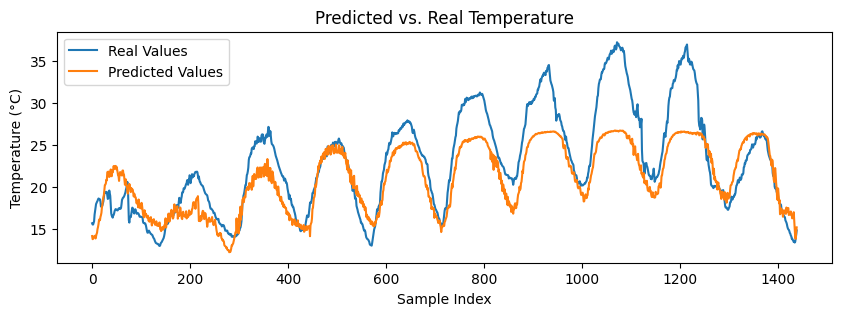

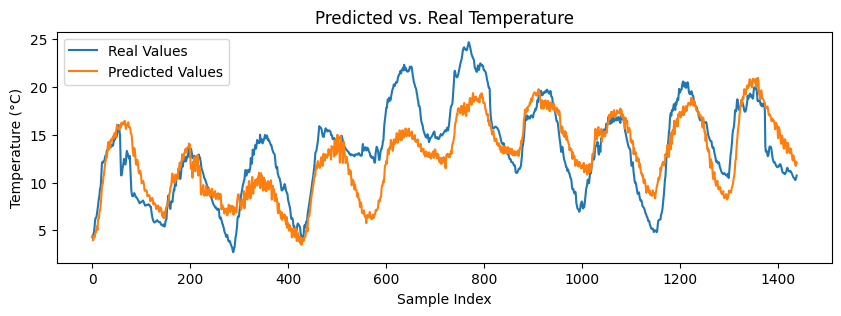

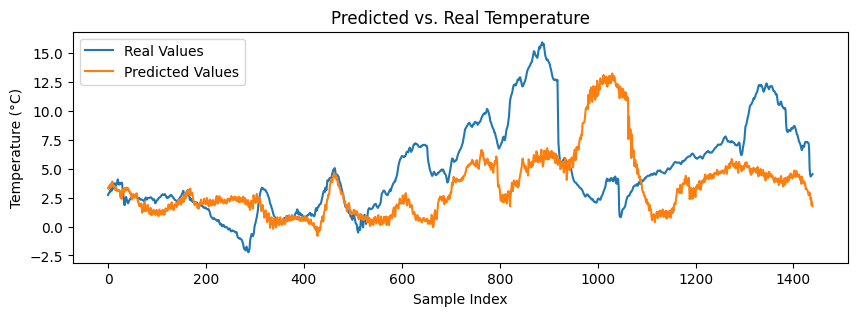

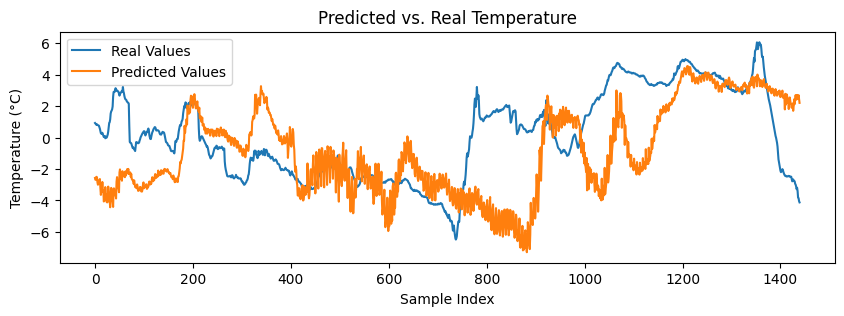

In [54]:
model = keras.models.load_model("models/jena_bi_lstm.keras")
for start_index in [ 24*6*6*29,  24*6*4*29, 24, 24*6*1*29,]:
    plot_predictions(test_dataset, model, 24*6*10, start_index)

In [55]:
results_df

,Model Name,Details,Train MAE,Val MAE,Test MAE,Train RMSE,Val RMSE,Test RMSE,Epochs,Time (s)
0,Baseline,Previous day,2.691644,2.441733,2.622036,3.492441,3.177835,3.426826,0,-1.000000
1,jena_mlp.keras,,2.129634,2.589282,2.672652,2.702645,3.279459,3.397715,10,604.268048
2,jena_cnn.keras,,3.027277,3.077919,3.303079,3.827525,3.900535,4.189565,10,1017.088803
3,jena_simpleRNN.keras,,2.448694,2.324813,2.502647,3.144267,2.990824,3.226822,10,816.164491
4,jena_lstm.keras,,2.317899,2.362597,2.615515,2.965745,3.049811,3.386308,14,1663.462876
5,jena_gru.keras,,2.351283,2.424803,2.506056,3.010933,3.178030,3.193945,10,1378.518566
6,jena_reg_lstm.keras,,2.337568,2.314306,2.495306,2.991771,2.988857,3.172751,30,5537.813763
7,jena_layered_gru.keras,,2.300835,2.297789,2.496914,2.937477,2.972229,3.190335,20,4436.961320
8,jena_layer_norm_GRU.keras,,2.292595,2.271889,2.419856,2.931269,2.928936,3.081884,20,4831.872897
9,jena_bi_lstm.keras,,2.242610,2.302074,2.438604,2.873965,2.959759,3.120723,10,2366.750035


In [56]:
###############################################
# Load TensorBoard notebook extension
%load_ext tensorboard

# Start TensorBoard before training begins
%tensorboard --logdir logs_jena  --reload_interval=1

<IPython.core.display.Javascript object>